# Experiment 0B: can the saved features support the benchmark?

**Why this notebook.** After full extraction, 0B checks that every planned feature artifact exists for every dataset and extractor, and that each predictor runs on full folds within its resources, before any comparative result is computed.

| Figure | Question | Shows |
|---|---|---|
| Representation inventory | Is every per-column and joint artifact present? | stored artifacts per extractor and dataset, as completed / planned |
| Predictor qualification | Which real runtime and resource checks remain? | current contract evidence and passing / required full-fold profiles for all nine predictors |

The qualification panel separates current predictor contracts from full-fold profiles. The representation inventory appears when saved feature artifacts exist. Manifest counts are an inventory; complete row, probability and blob validation belongs to the 0B test jobs.

## 1. Scope and provenance

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = '3. experiment_0/02_after_feature_creation'
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())


## 2. Saved representation inventory

Two representations are planned for each extractor/dataset. This counts stored manifest types across versions and does not approve a selected artifact.

In [2]:
report_section('2. Saved representation inventory')
from src.evaluation.notebook_study import artifact_coverage, predictor_evidence
from src.visualize.study import coverage_figures
inventory = artifact_coverage()
display_table("Saved representation types; not 0B acceptance", inventory, preview_rows=12)
for fig, name, caption in coverage_figures(inventory, "Stored separate/joint representations"):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)


dataset_id,model_id,planned,completed
BIN_TEXT_FAKE_JOB_POSTING,jev,2,0
BIN_TEXT_FAKE_JOB_POSTING,liquid,2,0
BIN_TEXT_FAKE_JOB_POSTING,liquid_lfm3,2,0
BIN_TEXT_FAKE_JOB_POSTING,perplexity,2,0
BIN_TEXT_FAKE_JOB_POSTING,cloudflare,2,0
BIN_TEXT_FAKE_JOB_POSTING,strands,2,0
BIN_TEXT_FAKE_JOB_POSTING,intern,2,0
BIN_TEXT_FAKE_JOB_POSTING,h2o,2,0
BIN_TEXT_FAKE_JOB_POSTING,sii,2,0
BIN_TEXT_FAKE_JOB_POSTING,kev,2,0


## 3. Predictor contracts and full-fold feasibility

All six fixed predictors and three native-text systems require real runtime checks. Historical reports must not stand in for the current evaluation identity.

model,configured_packages,contract_status,current_evaluation_identity,contract_passed,profiles_passed,profiles_required,full_fold_profile,source
catboost,"{""catboost"": ""1.2.10""}",not found locally,None,False,0,5,False,None
tabpfn_3_5,"{""tabpfn"": ""9.0.0""}",not found locally,None,False,0,5,False,None
tabicl_v2,"{""tabicl"": ""2.2.0""}",not found locally,None,False,0,5,False,None
limix_2,"{""LimiX"": ""git:516bf396333feb3198cf7aff8a6c10421f218e24""}",not found locally,None,False,0,5,False,None
kumo_tabular,"{""structured-data-models"": ""git:bd2d55db104679393fcd6afe13305f37e40b5467""}",not found locally,None,False,0,5,False,None
linear,"{""scikit-learn"": ""1.9.1""}",not found locally,None,False,0,5,False,None
tabstar,"{""tabstar"": ""1.2.2"", ""transformers"": ""4.57.6""}",not found locally,None,False,0,1,False,None
contexttab,"{""sap-rpt-oss"": ""git:a0067b3c9db56bc35a6dcab09a9223a3ff0821e0""}",not found locally,None,False,0,1,False,None
ag_mm,"{""autogluon.multimodal"": ""1.6.1""}",not found locally,None,False,0,1,False,None


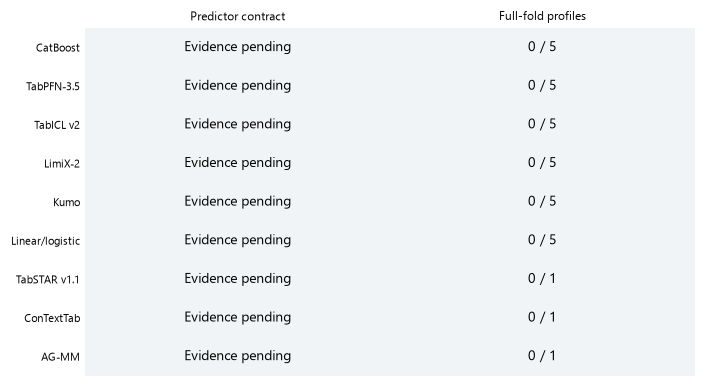

In [3]:
report_section('3. Predictor contracts and full-fold feasibility')
predictors = predictor_evidence()
display_table("Nine predictor evidence records", predictors, preview_rows=9)
from src.visualize.study import qualification_figure
fig = qualification_figure(predictors)
save(fig, "predictor_qualification", caption="Experiment 0B evidence for each predictor. The left column reports a current synthetic task-contract fit on VSC. The right column gives passing versus required first-outer-fold profiles on real data using the same runtime. Shading marks complete local evidence.")
display_local(fig)
plt.close(fig)
record("Required: binary, multiclass including 30 classes, regression, categorical/missing input, joint PCA64 and separate PCA32 at both encoder widths, native text, restart, prediction storage and actual full-training-fold feasibility for both PCA recipes. The benchmark gate checks complete decision and embedding artifacts, prepared PCA for every outer and binary inner training partition, prediction row IDs, and the sealed runtime.", "0B requirements")

## Complete printed report

Everything displayed above is printed in section order. Individual predictions and the full metric store remain available in the referenced evaluation databases.

In [4]:
finish_report(NOTEBOOK, save.summary() + "\nNo fitting, inference or outcome-based method selection was performed.")

3. experiment_0/02_after_feature_creation

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "94107650bd2b3268dfdd67e28eaa7600548f6960be47d3504d0f7f227af048e6",
  "git_head": "35bd49fee59371fdf716bc953e8d49fa5934320c",
  "git_dirty": true,
  "tfm_library_pin": "286157a5f8a4b6c53cf1341309e81bd1ff4ce128 dm-library (remotes/origin/HEAD)\n 8f14e5945ca6b068ed0c76218e769d3e672d0d13 tfm-library (remotes/origin/HEAD)\n 914ef4e57e1f153080e2686d03179c223db38c9a vsc-library (remotes/origin/HEAD)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Saved representation inventory


Saved representation types; not 0B acceptance
                    dataset_id    model_id  planned  completed
     BIN_TEXT_FAKE_JOB_POSTING         jev        2          0
     BIN_TEXT_FAKE_JOB_POSTING      liquid        2          0
     BIN_TEXT_FAKE_JOB_POS